# Scenario 1:
## Flight Delay Analysis

**Problem Statement:**
An airline tracks flight delays (in minutes) for 20 flights. Analyze the flight delays to calculate percentiles, detect outliers, and evaluate the overall distribution.

**Objectives:**
1. Calculate Percentiles (25th, 50th, 75th, 90th, 95th)
2. Detect Outliers using IQR Method
3. Evaluate Overall Distribution with Histogram and BoxPlot

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 20 Flights Delay Data (in minutes) - Example data, replace with actual
flight_delays = [5, 10, 15, 12, 8, 20, 25, 30, 5, 45, 
                 10, 18, 22, 60, 7, 14, 28, 12, 9, 100]

print("Flight Delays Data:", flight_delays)
print("Total Flights:", len(flight_delays))

Flight Delays Data: [5, 10, 15, 12, 8, 20, 25, 30, 5, 45, 10, 18, 22, 60, 7, 14, 28, 12, 9, 100]
Total Flights: 20


In [2]:
# Percentile Calculation
p25 = np.percentile(flight_delays, 25)
p50 = np.percentile(flight_delays, 50)
p75 = np.percentile(flight_delays, 75)
p90 = np.percentile(flight_delays, 90)
p95 = np.percentile(flight_delays, 95)

print(f"25th Percentile: {p25} mins")
print(f"50th Percentile (Median): {p50} mins")
print(f"75th Percentile: {p75} mins")
print(f"90th Percentile: {p90} mins")
print(f"95th Percentile: {p95} mins")

25th Percentile: 9.75 mins
50th Percentile (Median): 14.5 mins
75th Percentile: 25.75 mins
90th Percentile: 46.50000000000002 mins
95th Percentile: 62.00000000000003 mins


In [5]:
# Outlier Detection
Q1 = np.percentile(flight_delays, 25)
Q3 = np.percentile(flight_delays, 75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = [x for x in flight_delays if x < lower_bound or x > upper_bound]

print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Bounds: [{lower_bound:.2f} , {upper_bound:.2f}]")
print(f"Outliers Detected: {outliers}")
if outliers:
    print(f" {len(outliers)} flights are highly delayed!")
else:
    print(" No significant outliers")

Q1: 9.75, Q3: 25.75, IQR: 16.0
Bounds: [-14.25 , 49.75]
Outliers Detected: [60, 100]
 2 flights are highly delayed!


Mean Delay: 22.75 mins
Median Delay: 14.5 mins
Std Dev: 22.30
Min: 5 mins, Max: 100 mins


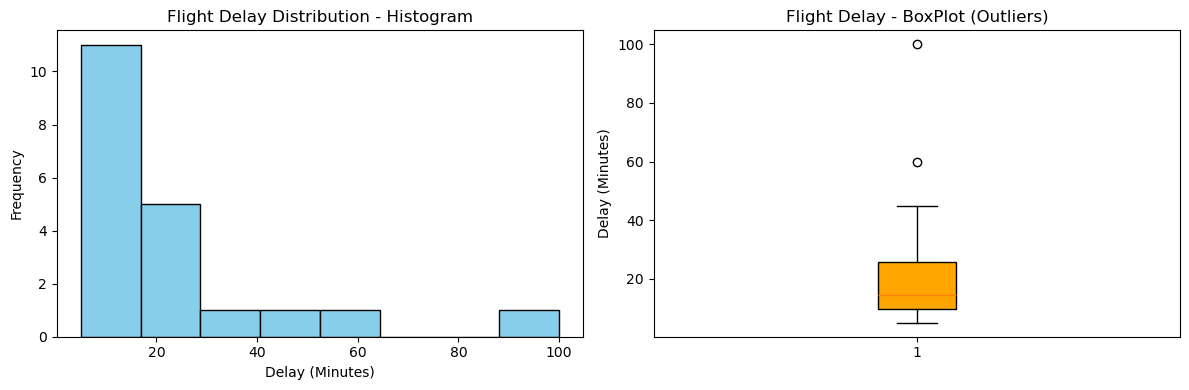

In [6]:
# Distribution Stats
print(f"Mean Delay: {np.mean(flight_delays):.2f} mins")
print(f"Median Delay: {np.median(flight_delays)} mins")
print(f"Std Dev: {np.std(flight_delays):.2f}")
print(f"Min: {min(flight_delays)} mins, Max: {max(flight_delays)} mins")

# Histogram
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.hist(flight_delays, bins=8, color='skyblue', edgecolor='black')
plt.title('Flight Delay Distribution - Histogram')
plt.xlabel('Delay (Minutes)')
plt.ylabel('Frequency')

# BoxPlot - Best for outlier visualization
plt.subplot(1,2,2)
plt.boxplot(flight_delays, patch_artist=True, boxprops=dict(facecolor='orange'))
plt.title('Flight Delay - BoxPlot (Outliers)')
plt.ylabel('Delay (Minutes)')

plt.tight_layout()
plt.show()

# Scenario 2:
## Employee Salary Analysis

**Problem Statement:**
A company wants to analyze the salary distribution of its employees to understand the central tendency and determine whether the data is skewed.

**Objectives:**
1. Calculate Central Tendency - Mean, Median, Mode
2. Check Skewness of the data (Normal / Positively Skewed / Negatively Skewed)
3. Visualize Distribution with Histogram

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Employee Salary Data (in thousands / Rupees) - Example data
salaries = [30000, 32000, 35000, 38000, 40000, 42000, 45000, 48000, 50000, 52000,
            55000, 58000, 60000, 65000, 70000, 75000, 80000, 85000, 120000, 150000]

print("Salary Data:", salaries)
print("Total Employees:", len(salaries))


Salary Data: [30000, 32000, 35000, 38000, 40000, 42000, 45000, 48000, 50000, 52000, 55000, 58000, 60000, 65000, 70000, 75000, 80000, 85000, 120000, 150000]
Total Employees: 20


In [9]:
# Central Tendency
mean_salary = np.mean(salaries)
median_salary = np.median(salaries)
mode_result = stats.mode(salaries, keepdims=True)
mode_salary = mode_result.mode[0] if len(salaries) > 0 else "No mode"

print(f"Mean Salary: Rs. {mean_salary:.2f}")
print(f"Median Salary: Rs. {median_salary:.2f}")
print(f"Mode Salary: Rs. {mode_salary}")

# Comparison 

if mean_salary > median_salary:
    print("Mean > Median -> Possible Positive Skew (High earners pulling mean up)")
elif mean_salary < median_salary:
    print("Mean < Median -> Possible Negative Skew")
else:
    print("Mean = Median -> Symmetric distribution")

Mean Salary: Rs. 61500.00
Median Salary: Rs. 53500.00
Mode Salary: Rs. 30000
Mean > Median -> Possible Positive Skew (High earners pulling mean up)


In [11]:
# Skewness Calculation
skewness = stats.skew(salaries)
print(f"Skewness Value: {skewness:.4f}")

if skewness > 0.5:
    print("Result: Positively Skewed (Right Skewed) - Most employees earn less, few earn very high")
    print(" Common in salary data due to managers/CEOs")
elif skewness -0.5:
    print("Result: Negatively Skewed (Left Skewed)")
else:
    print("Result: Approximately Normal / Symmetric - Salaries are balanced")



Skewness Value: 1.5992
Result: Positively Skewed (Right Skewed) - Most employees earn less, few earn very high
 Common in salary data due to managers/CEOs


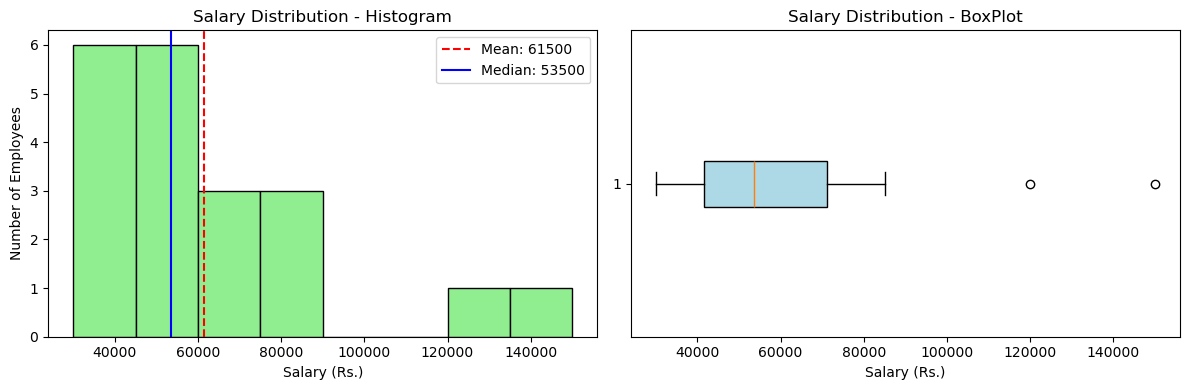

In [12]:
# Visualization
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.hist(salaries, bins=8, color='lightgreen', edgecolor='black')
plt.axvline(mean_salary, color='red', linestyle='--', label=f'Mean: {mean_salary:.0f}')
plt.axvline(median_salary, color='blue', linestyle='-', label=f'Median: {median_salary:.0f}')
plt.title('Salary Distribution - Histogram')
plt.xlabel('Salary (Rs.)')
plt.ylabel('Number of Employees')
plt.legend()

plt.subplot(1,2,2)
plt.boxplot(salaries, vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue'))
plt.title('Salary Distribution - BoxPlot')
plt.xlabel('Salary (Rs.)')

plt.tight_layout()
plt.show()

# Scenario 3:
## Product Sales Analysis

**Problem Statement:**
A retail store records product sales over 15 days. Create a frequency distribution table and visualize the sales data using appropriate charts.

**Objectives:**
1. Create Frequency Distribution Table
2. Visualize with Histogram, Bar Chart, Line Chart
3. Understand Sales Trend over 15 days

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Product Sales Data for 15 days - Example data
sales_data = [120, 150, 130, 180, 200, 170, 160, 190, 210, 220, 180, 175, 195, 205, 230]
days = [f"Day {i+1}" for i in range(15)]

df = pd.DataFrame({'Day': days, 'Sales': sales_data})
print(df)
print(f"\nTotal Sales in 15 days: {sum(sales_data)}")

       Day  Sales
0    Day 1    120
1    Day 2    150
2    Day 3    130
3    Day 4    180
4    Day 5    200
5    Day 6    170
6    Day 7    160
7    Day 8    190
8    Day 9    210
9   Day 10    220
10  Day 11    180
11  Day 12    175
12  Day 13    195
13  Day 14    205
14  Day 15    230

Total Sales in 15 days: 2715


In [15]:
# Frequency Distribution Table
# Define bins (sales ranges)
bins = [0, 150, 180, 210, 250]  # 0-150, 150-180, 180-210, 210-250
labels = ['0-150', '150-180', '180-210', '210-250']

df['Sales_Range'] = pd.cut(df['Sales'], bins=bins, labels=labels)

freq_table = df['Sales_Range'].value_counts().sort_index()
freq_table_df = pd.DataFrame({
    'Sales Range': freq_table.index,
    'Frequency (No. of Days)': freq_table.values,
    'Percentage': (freq_table.values / len(df) * 100).round(2)
})

print(" Frequency Distribution Table ")
print(freq_table_df)

# Also using numpy histogram for detailed
counts, bin_edges = np.histogram(sales_data, bins=bins)
print(f"\nBin Edges: {bin_edges}")
print(f"Counts: {counts}")

 Frequency Distribution Table 
  Sales Range  Frequency (No. of Days)  Percentage
0       0-150                        3       20.00
1     150-180                        5       33.33
2     180-210                        5       33.33
3     210-250                        2       13.33

Bin Edges: [  0 150 180 210 250]
Counts: [2 4 6 3]


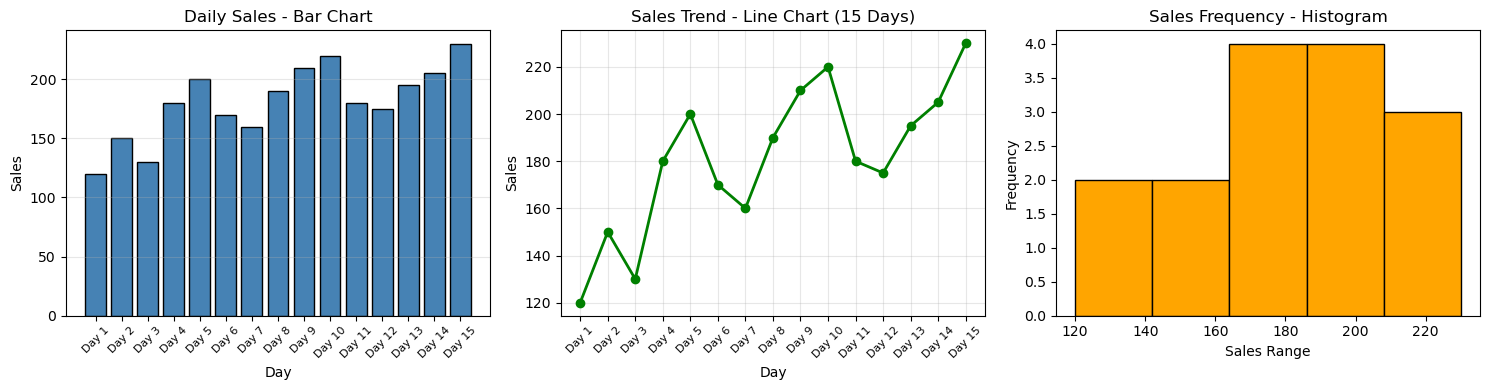

In [16]:
# Visualization - 3 Charts
plt.figure(figsize=(15,4))

# Chart 1: Bar Chart - Sales per Day
plt.subplot(1,3,1)
plt.bar(days, sales_data, color='steelblue', edgecolor='black')
plt.title('Daily Sales - Bar Chart')
plt.xlabel('Day')
plt.ylabel('Sales')
plt.xticks(rotation=45, fontsize=8)
plt.grid(axis='y', alpha=0.3)

# Chart 2: Line Chart - Trend
plt.subplot(1,3,2)
plt.plot(days, sales_data, marker='o', color='green', linewidth=2, markersize=6)
plt.title('Sales Trend - Line Chart (15 Days)')
plt.xlabel('Day')
plt.ylabel('Sales')
plt.xticks(rotation=45, fontsize=8)
plt.grid(True, alpha=0.3)

# Chart 3: Histogram - Frequency Distribution
plt.subplot(1,3,3)
plt.hist(sales_data, bins=5, color='orange', edgecolor='black')
plt.title('Sales Frequency - Histogram')
plt.xlabel('Sales Range')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

# Scenario 4:
## Student Exam Performance Analysis

**Problem Statement:**
A school wants to analyze the exam performance of students across three subjects: Mathematics, Science, and English. How can Data Science concepts be applied to understand their performance?

**Objectives:**
1. Descriptive Statistics for each subject
2. Compare performance across subjects
3. Identify weak subjects and top performers
4. Visualize with Bar Chart, BoxPlot, Heatmap (Correlation)

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Student Marks Data - 15 students example

data = {
    'Student': [f'Stud_{i+1}' for i in range(15)],
    'Mathematics': [85, 78, 92, 65, 70, 88, 90, 75, 80, 82, 95, 68, 77, 89, 91],
    'Science':     [80, 75, 88, 60, 68, 85, 87, 72, 78, 80, 90, 65, 74, 86, 88],
    'English':     [78, 82, 85, 70, 75, 80, 82, 88, 85, 79, 92, 72, 80, 84, 90]
}

df = pd.DataFrame(data)
print(df.head(10))
print(f"\nTotal Students: {len(df)}")

   Student  Mathematics  Science  English
0   Stud_1           85       80       78
1   Stud_2           78       75       82
2   Stud_3           92       88       85
3   Stud_4           65       60       70
4   Stud_5           70       68       75
5   Stud_6           88       85       80
6   Stud_7           90       87       82
7   Stud_8           75       72       88
8   Stud_9           80       78       85
9  Stud_10           82       80       79

Total Students: 15


In [18]:
# Descriptive Stats
print("=== Descriptive Statistics ===")
desc = df[['Mathematics','Science','English']].describe()
print(desc)

# Central Tendency detailed
for subject in ['Mathematics','Science','English']:
    mean_val = df[subject].mean()
    median_val = df[subject].median()
    mode_val = df[subject].mode()[0]
    std_val = df[subject].std()
    skew_val = stats.skew(df[subject])
    
    print(f"\n{subject}:")
    print(f"  Mean: {mean_val:.2f}, Median: {median_val}, Mode: {mode_val}")
    print(f"  Std Dev: {std_val:.2f} (Spread), Skew: {skew_val:.2f}")

=== Descriptive Statistics ===
       Mathematics    Science    English
count    15.000000  15.000000  15.000000
mean     81.666667  78.400000  81.466667
std       9.370674   9.248938   6.232022
min      65.000000  60.000000  70.000000
25%      76.000000  73.000000  78.500000
50%      82.000000  80.000000  82.000000
75%      89.500000  86.500000  85.000000
max      95.000000  90.000000  92.000000

Mathematics:
  Mean: 81.67, Median: 82.0, Mode: 65
  Std Dev: 9.37 (Spread), Skew: -0.33

Science:
  Mean: 78.40, Median: 80.0, Mode: 80
  Std Dev: 9.25 (Spread), Skew: -0.51

English:
  Mean: 81.47, Median: 82.0, Mode: 80
  Std Dev: 6.23 (Spread), Skew: -0.16


In [19]:
# Performance Comparison
subject_means = df[['Mathematics','Science','English']].mean()
print("Average Performance by Subject:")
print(subject_means)

# Find toughest subject
toughest = subject_means.idxmin()
easiest = subject_means.idxmax()
print(f"\nToughest Subject (Lowest Avg): {toughest} - {subject_means[toughest]:.2f}")
print(f"Easiest Subject (Highest Avg): {easiest} - {subject_means[easiest]:.2f}")

# Overall performance per student
df['Total'] = df['Mathematics'] + df['Science'] + df['English']
df['Average'] = df['Total'] / 3
df['Grade'] = pd.cut(df['Average'], bins=[0,60,70,80,90,100], labels=['F','C','B','A','A+'])

print(" Top 5 Students")
print(df.sort_values('Average', ascending=False)[['Student','Total','Average','Grade']].head())

print(" Students Needing Help (<70 avg) ")
print(df[df['Average'] < 70][['Student','Mathematics','Science','English','Average']])

Average Performance by Subject:
Mathematics    81.666667
Science        78.400000
English        81.466667
dtype: float64

Toughest Subject (Lowest Avg): Science - 78.40
Easiest Subject (Highest Avg): Mathematics - 81.67
 Top 5 Students
    Student  Total    Average Grade
10  Stud_11    277  92.333333    A+
14  Stud_15    269  89.666667     A
2    Stud_3    265  88.333333     A
6    Stud_7    259  86.333333     A
13  Stud_14    259  86.333333     A
 Students Needing Help (<70 avg) 
    Student  Mathematics  Science  English    Average
3    Stud_4           65       60       70  65.000000
11  Stud_12           68       65       72  68.333333


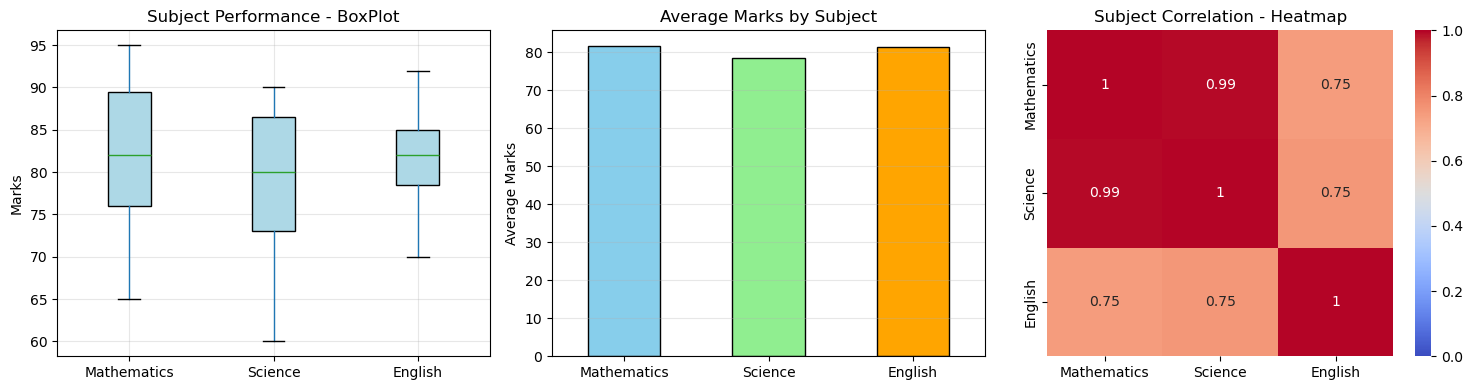

Correlation Matrix:
             Mathematics   Science   English
Mathematics     1.000000  0.993932  0.745293
Science         0.993932  1.000000  0.754938
English         0.745293  0.754938  1.000000


In [20]:
# Visualization - 3 Charts
plt.figure(figsize=(15,4))

# Chart 1: BoxPlot - Subject-wise distribution & outliers
plt.subplot(1,3,1)
df[['Mathematics','Science','English']].boxplot(patch_artist=True,
    boxprops=dict(facecolor='lightblue'))
plt.title('Subject Performance - BoxPlot')
plt.ylabel('Marks')
plt.grid(alpha=0.3)

# Chart 2: Bar Chart - Average marks per subject
plt.subplot(1,3,2)
subject_means.plot(kind='bar', color=['skyblue','lightgreen','orange'], edgecolor='black')
plt.title('Average Marks by Subject')
plt.ylabel('Average Marks')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

# Chart 3: Correlation Heatmap - Do students good in one subject do well in others?
plt.subplot(1,3,3)
corr = df[['Mathematics','Science','English']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=0, vmax=1)
plt.title('Subject Correlation - Heatmap')

plt.tight_layout()
plt.show()

print("Correlation Matrix:")
print(corr)

# Scenario 5:
## Clinical Trial for Diabetes Medication

**Problem Statement:**
A pharmaceutical company conducted a clinical trial with two groups: one receiving medication and the other a placebo. Perform a hypothesis test to determine the effectiveness of the medication.

**Objectives:**
1. Define Null and Alternate Hypothesis
2. Perform Two-Sample T-Test (Independent)
3. Interpret P-Value and Conclusion
4. Visualize Distribution of Blood Sugar Levels

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Clinical Trial Data - Blood Sugar Level (mg/dL) after treatment
# Example data - Replace with actual data
# Lower blood sugar = Medication working

medication_group = [120, 115, 130, 118, 122, 110, 125, 119, 121, 117, 123, 116, 124, 112, 128]  # Treatment
placebo_group =     [140, 135, 150, 138, 142, 145, 148, 139, 141, 143, 146, 137, 149, 144, 152]  # Placebo

print(f"Medication Group (n={len(medication_group)}): Mean = {np.mean(medication_group):.2f} mg/dL")
print(f"Placebo Group (n={len(placebo_group)}): Mean = {np.mean(placebo_group):.2f} mg/dL")
print(f"\nDifference: {np.mean(placebo_group) - np.mean(medication_group):.2f} mg/dL lower with medication")

Medication Group (n=15): Mean = 120.00 mg/dL
Placebo Group (n=15): Mean = 143.27 mg/dL

Difference: 23.27 mg/dL lower with medication


In [23]:
# 2. Hypothesis Test - Independent Two-Sample T-Test

# Check assumptions quickly
_, p_med = stats.shapiro(medication_group)
_, p_pla = stats.shapiro(placebo_group)
print(f"Medication group normality p-value: {p_med:.4f} (>0.05 = Normal)")
print(f"Placebo group normality p-value: {p_pla:.4f} (>0.05 = Normal)")

print("T-Test for Effectiveness")
# Perform t-test (assuming unequal variance - Welch's t-test)
t_stat, p_value = stats.ttest_ind(medication_group, placebo_group, equal_var=False)

print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_value:.10f}")

# One-tailed test for "medication reduces sugar" (more powerful)
t_stat_one, p_value_one = stats.ttest_ind(medication_group, placebo_group, alternative='less')
print(f"\nOne-tailed (Med < Placebo) - P-Value: {p_value_one:.10f}")

alpha = 0.05
print(f"\nAlpha = {alpha}")
if p_value < alpha:
    print(f"Result: p-value ({p_value:.6f}) < alpha ({alpha})")
    print(" REJECT Null Hypothesis (H0)")
    print(" CONCLUSION: Medication is EFFECTIVE! Significant difference in blood sugar levels.")
else:
    print(f"Result: p-value ({p_value:.6f}) >= alpha ({alpha})")
    print("=> FAIL TO REJECT Null Hypothesis (H0)")
    print("=> CONCLUSION: Medication is NOT significantly effective.")

Medication group normality p-value: 0.9998 (>0.05 = Normal)
Placebo group normality p-value: 0.9562 (>0.05 = Normal)
T-Test for Effectiveness
T-Statistic: -11.9435
P-Value: 0.0000000000

One-tailed (Med < Placebo) - P-Value: 0.0000000000

Alpha = 0.05
Result: p-value (0.000000) < alpha (0.05)
 REJECT Null Hypothesis (H0)
 CONCLUSION: Medication is EFFECTIVE! Significant difference in blood sugar levels.


C:\Users\DELL\AppData\Local\Temp\ipykernel_7660\4266877198.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([medication_group, placebo_group], labels=['Medication','Placebo'],


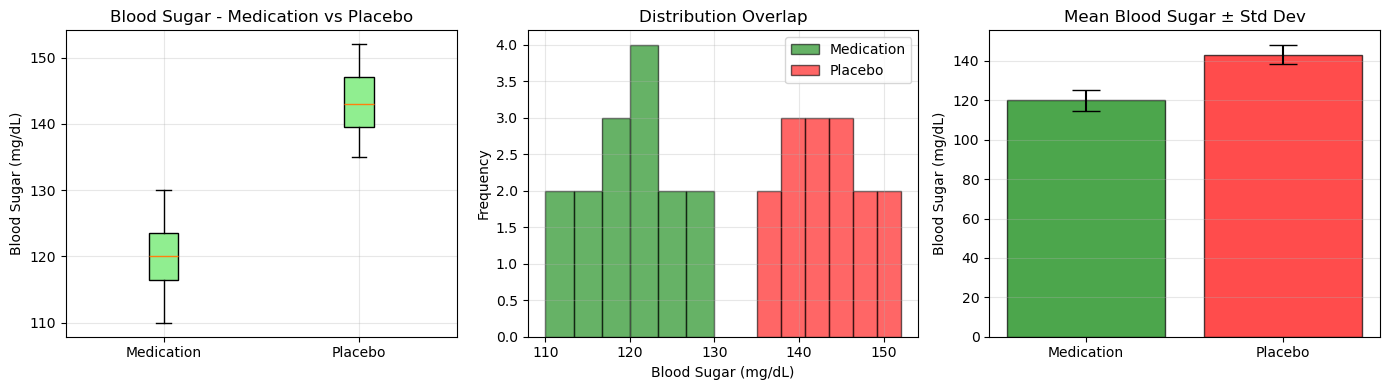

In [24]:
# Visualization
plt.figure(figsize=(14,4))

# Chart 1: BoxPlot Comparison
plt.subplot(1,3,1)
plt.boxplot([medication_group, placebo_group], labels=['Medication','Placebo'],
            patch_artist=True, boxprops=dict(facecolor='lightgreen'))
plt.title('Blood Sugar - Medication vs Placebo')
plt.ylabel('Blood Sugar (mg/dL)')
plt.grid(alpha=0.3)

# Chart 2: Histogram Overlap
plt.subplot(1,3,2)
plt.hist(medication_group, bins=6, alpha=0.6, label='Medication', color='green', edgecolor='black')
plt.hist(placebo_group, bins=6, alpha=0.6, label='Placebo', color='red', edgecolor='black')
plt.title('Distribution Overlap')
plt.xlabel('Blood Sugar (mg/dL)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(alpha=0.3)

# Chart 3: Bar Chart - Mean with Std Dev
plt.subplot(1,3,3)
means = [np.mean(medication_group), np.mean(placebo_group)]
stds = [np.std(medication_group), np.std(placebo_group)]
plt.bar(['Medication','Placebo'], means, yerr=stds, capsize=10,
        color=['green','red'], alpha=0.7, edgecolor='black')
plt.title('Mean Blood Sugar ± Std Dev')
plt.ylabel('Blood Sugar (mg/dL)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()